# **Prediksi Customer Churn pada Data Telekomunikasi Menggunakan XGBoost  dan Support Vector Machine**

### **Kelompok 11**
### **1. Shakyla Andhara Chandraningtyas (24031554199)**
### **2. Desnanty Ratna Aulia (24031554163)**
### **3. Fajria Rasmi Ridha Rumkel (24031554191)**

# **Install dan Import Library**

In [ ]:
!pip install -q xgboost imbalanced-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

# **Mount Google Drive**

In [ ]:
drive.mount('/content/drive')
base_path = "/content/drive/Shareddrives/PROJECT PEMBELAJARAN MESIN KELOMPOK 11/synthetic_customer_churn_100k.csv"

Mounted at /content/drive


# **Load Dataset**

In [ ]:
df = pd.read_csv(base_path)
df.head()

,CustomerID,Age,Gender,Tenure,MonthlyCharges,Contract,PaymentMethod,TotalCharges,Churn
0,1,56,Female,68,147.58,Two year,Bank transfer,10052.03,No
1,2,69,Male,32,22.54,Month-to-month,Mailed check,686.78,No
2,3,46,Female,10,52.47,One year,Electronic check,537.88,No
3,4,32,Male,22,109.67,Month-to-month,Mailed check,2390.04,Yes
4,5,60,Female,54,130.98,Month-to-month,Credit card,7081.28,No


# **Cek Struktur Dataset**

In [ ]:
print("Jumlah baris dan kolom:", df.shape)
print("\nNama kolom:")
print(df.columns)
print("\nInformasi dataset:")
df.info()
print("\nStatistik deskriptif:")
display(df.describe())
print("\nDistribusi target Churn:")
print(df['Churn'].value_counts())

Jumlah baris dan kolom: (100000, 9)

Nama kolom:
Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'MonthlyCharges', 'Contract',
       'PaymentMethod', 'TotalCharges', 'Churn'],
      dtype='object')

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   CustomerID      100000 non-null  int64  
 1   Age             100000 non-null  int64  
 2   Gender          100000 non-null  object 
 3   Tenure          100000 non-null  int64  
 4   MonthlyCharges  100000 non-null  float64
 5   Contract        100000 non-null  object 
 6   PaymentMethod   100000 non-null  object 
 7   TotalCharges    100000 non-null  float64
 8   Churn           100000 non-null  object 
dtypes: float64(2), int64(3), object(4)
memory usage: 6.9+ MB

Statistik deskriptif:


,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,49.027240,36.527090,79.974933,2926.140256
std,28867.657797,18.177862,20.789552,40.491961,2388.163672
min,1.000000,18.000000,1.000000,10.000000,-118.430000
25%,25000.750000,33.000000,18.000000,44.720000,963.667500
50%,50000.500000,49.000000,37.000000,80.000000,2268.060000
75%,75000.250000,65.000000,54.000000,115.050000,4394.327500
max,100000.000000,80.000000,72.000000,150.000000,10831.460000



Distribusi target Churn:
Churn
No     66856
Yes    33144
Name: count, dtype: int64


# **Data Cleaning**

In [ ]:
df_clean = df.copy()

# Ubah TotalCharges menjadi numerik jika masih bertipe object
if 'TotalCharges' in df_clean.columns:
    df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

# Cek missing value
print("Missing value:")
print(df_clean.isnull().sum())

# Cek data duplikat
print("\nJumlah data duplikat:", df_clean.duplicated().sum())

# Hapus data duplikat jika ada
df_clean = df_clean.drop_duplicates()

# Cek nilai tidak wajar pada data numerik
numeric_columns = ['Age', 'Tenure', 'MonthlyCharges', 'TotalCharges']
numeric_check = df_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("\nNilai minimum setiap fitur numerik:")
print(df_clean[numeric_check].min())

print("\nNilai maksimum setiap fitur numerik:")
print(df_clean[numeric_check].max())

# Menangani nilai tidak wajar jika ada
if 'TotalCharges' in df_clean.columns:
    totalcharges_negatif = (df_clean['TotalCharges'] < 0).sum()
    print("\nJumlah TotalCharges negatif:", totalcharges_negatif)

    df_clean.loc[df_clean['TotalCharges'] < 0, 'TotalCharges'] = np.nan

kolom_tidak_boleh_negatif = ['Age', 'Tenure', 'MonthlyCharges', 'TotalCharges']

for col in kolom_tidak_boleh_negatif:
    if col in df_clean.columns:
        jumlah_negatif = (df_clean[col] < 0).sum()
        print(f"Jumlah {col} negatif:", jumlah_negatif)
        df_clean.loc[df_clean[col] < 0, col] = np.nan

print("\nShape setelah cleaning:", df_clean.shape)

Missing value:
CustomerID        0
Age               0
Gender            0
Tenure            0
MonthlyCharges    0
Contract          0
PaymentMethod     0
TotalCharges      0
Churn             0
dtype: int64

Jumlah data duplikat: 0

Nilai minimum setiap fitur numerik:
CustomerID          1.00
Age                18.00
Tenure              1.00
MonthlyCharges     10.00
TotalCharges     -118.43
dtype: float64

Nilai maksimum setiap fitur numerik:
CustomerID        100000.00
Age                   80.00
Tenure                72.00
MonthlyCharges       150.00
TotalCharges       10831.46
dtype: float64

Jumlah TotalCharges negatif: 265
Jumlah Age negatif: 0
Jumlah Tenure negatif: 0
Jumlah MonthlyCharges negatif: 0
Jumlah TotalCharges negatif: 0

Shape setelah cleaning: (100000, 9)


# **Outlier Detection Menggunakan Boxplot**

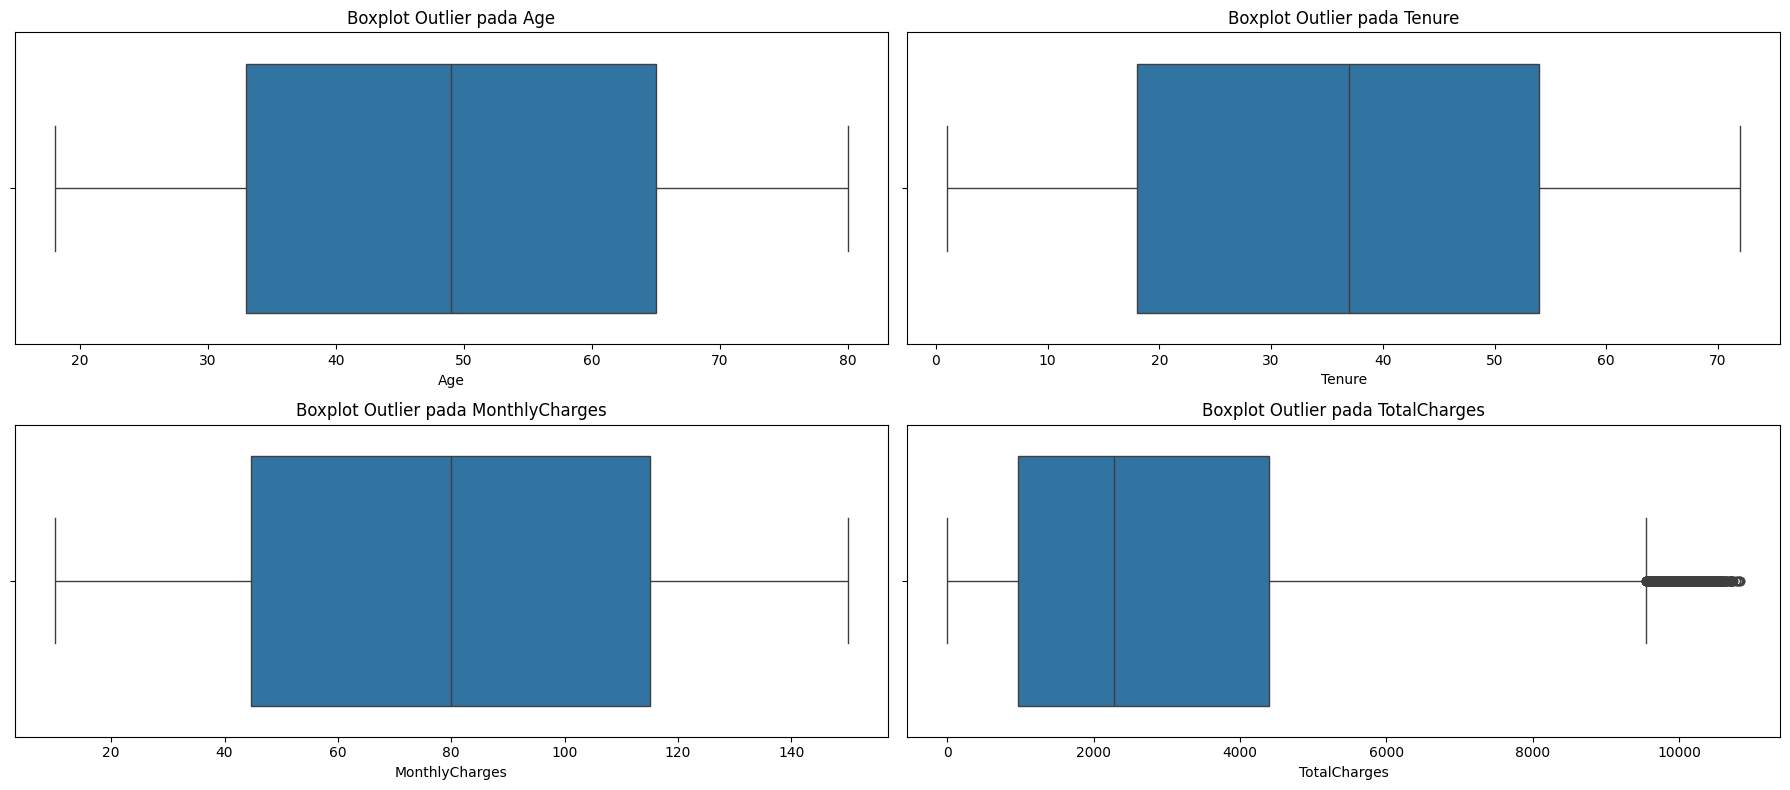

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_cols = 2
n_rows = math.ceil(len(numeric_columns) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4*n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    sns.boxplot(
        x=df_clean[col],
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot Outlier pada {col}")
    axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# **Outlier Detection Menggunakan IQR**

In [ ]:
outlier_summary = []

for col in numeric_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    jumlah_outlier = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()

    outlier_summary.append({
        'Fitur': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Jumlah Outlier': jumlah_outlier
    })

df_outlier = pd.DataFrame(outlier_summary)

display(df_outlier)

,Fitur,Q1,Q3,IQR,Lower Bound,Upper Bound,Jumlah Outlier
0,Age,33.000,65.000,32.00,-15.000,113.000,0
1,Tenure,18.000,54.000,36.00,-36.000,108.000,0
2,MonthlyCharges,44.720,115.050,70.33,-60.775,220.545,0
3,TotalCharges,972.425,4402.025,3429.60,-4171.975,9546.425,832


# **EDA: Distribusi Churn**

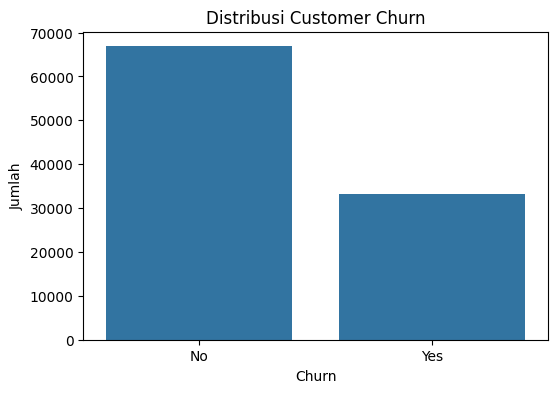

Jumlah data:
Churn
No     66856
Yes    33144
Name: count, dtype: int64

Persentase:
Churn
No     66.856
Yes    33.144
Name: proportion, dtype: float64


In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df_clean)
plt.title("Distribusi Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Jumlah")
plt.show()

print("Jumlah data:")
print(df_clean['Churn'].value_counts())

print("\nPersentase:")
print(df_clean['Churn'].value_counts(normalize=True) * 100)

# **EDA: Distribusi Fitur Numerik**

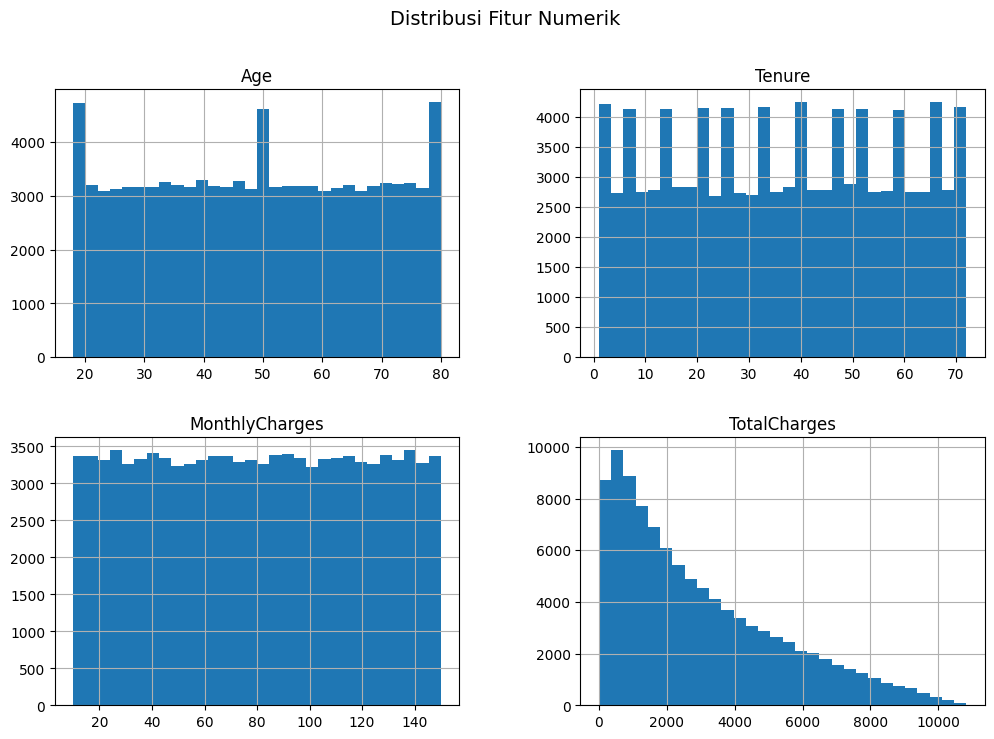

In [ ]:
df_clean[numeric_columns].hist(figsize=(12, 8), bins=30)
plt.suptitle("Distribusi Fitur Numerik", fontsize=14)
plt.show()

# **EDA: Distribusi Fitur Kategorik**

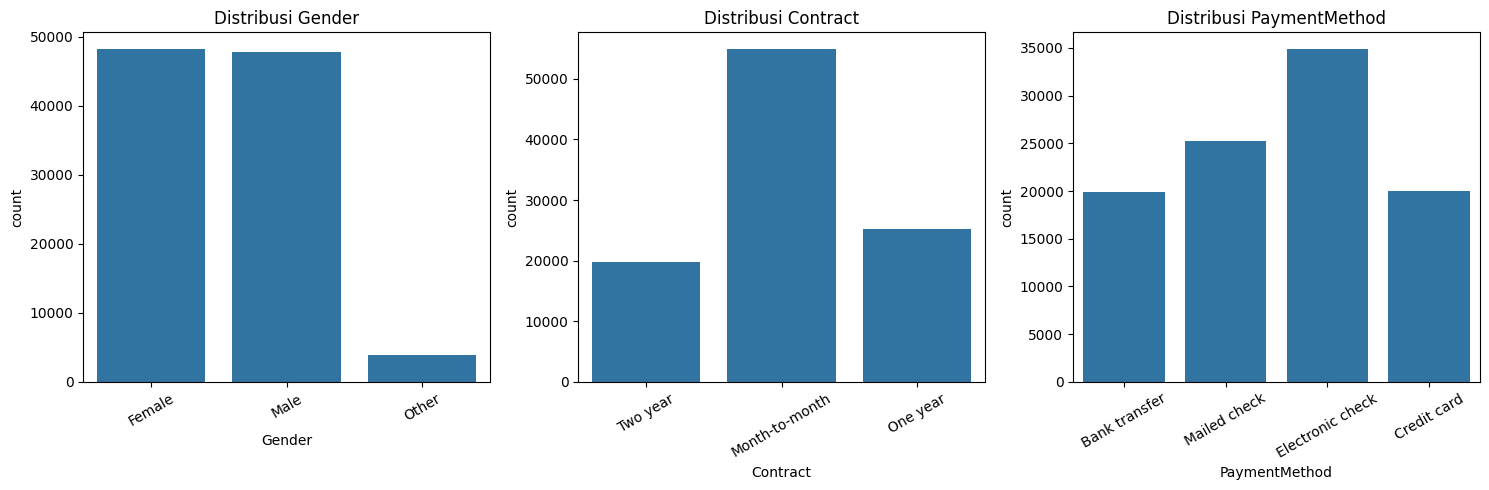

In [ ]:
import math

categorical_columns = df_clean.select_dtypes(include=['object']).columns.tolist()

if 'Churn' in categorical_columns:
    categorical_columns.remove('Churn')

if 'CustomerID' in categorical_columns:
    categorical_columns.remove('CustomerID')

n_cols = 3
n_rows = math.ceil(len(categorical_columns) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
axes = axes.flatten()

for i, col in enumerate(categorical_columns):
    sns.countplot(x=col, data=df_clean, ax=axes[i])
    axes[i].set_title(f"Distribusi {col}")
    axes[i].tick_params(axis='x', rotation=30)

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# **EDA: Fitur Kategorik vs Churn**

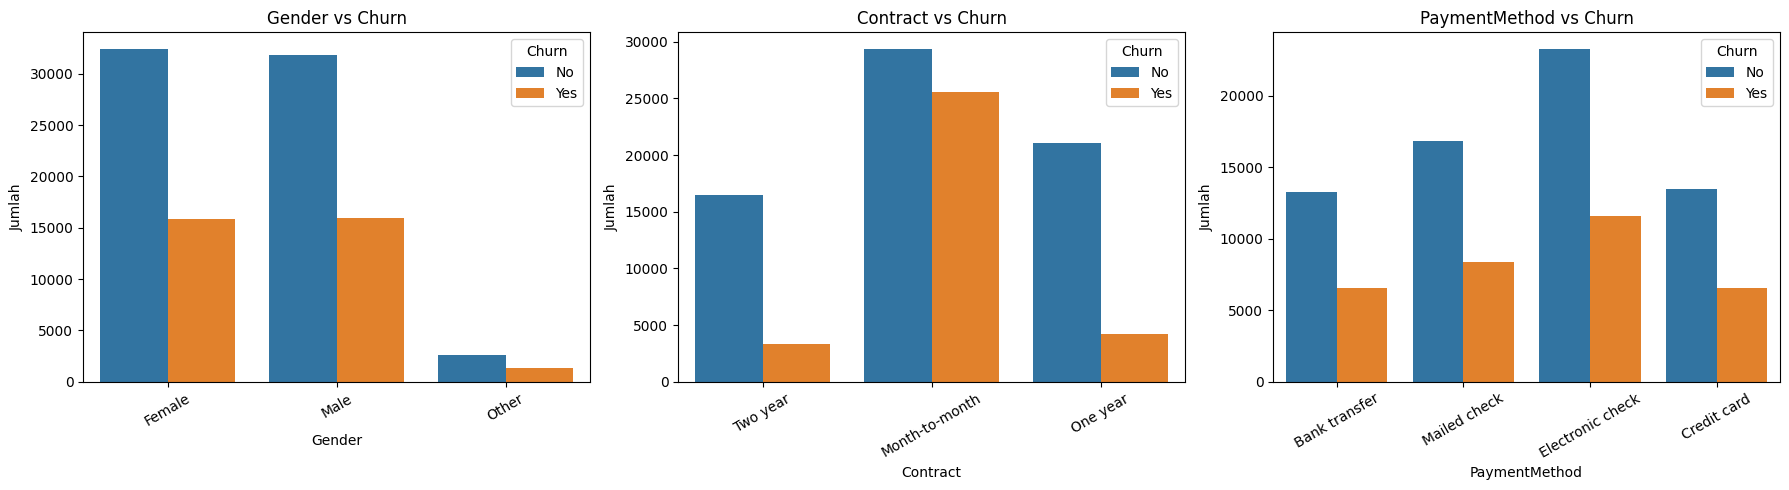

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_cols = 3
n_rows = math.ceil(len(categorical_columns) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
axes = axes.flatten()

for i, col in enumerate(categorical_columns):
    sns.countplot(
        x=col,
        hue='Churn',
        data=df_clean,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Churn")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Jumlah")
    axes[i].tick_params(axis='x', rotation=30)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# **EDA: MonthlyCharges vs Churn**

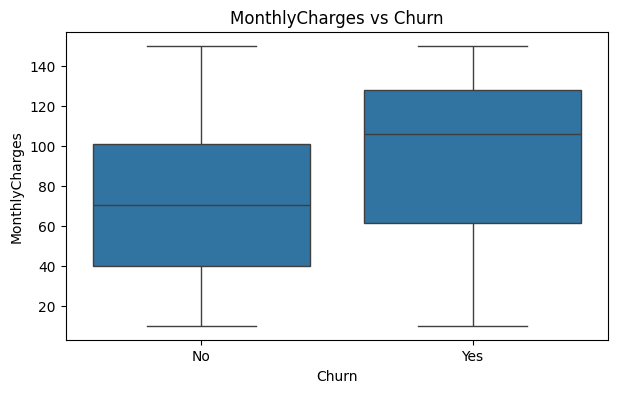

In [ ]:
if 'MonthlyCharges' in df_clean.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x='Churn', y='MonthlyCharges', data=df_clean)
    plt.title("MonthlyCharges vs Churn")
    plt.xlabel("Churn")
    plt.ylabel("MonthlyCharges")
    plt.show()

# **EDA: Heatmap Korelasi Fitur Numerik**

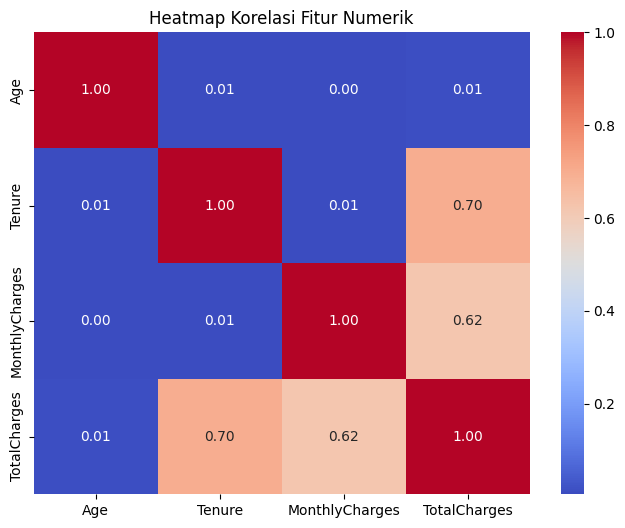

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df_clean[numeric_columns].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Heatmap Korelasi Fitur Numerik")
plt.show()

# **Encoding Target**

In [ ]:
df_model = df_clean.copy()

# Encoding target Churn
if df_model['Churn'].dtype == 'object':
    df_model['Churn'] = df_model['Churn'].map({
        'No': 0,
        'Yes': 1
    })

print("Distribusi target setelah encoding:")
print(df_model['Churn'].value_counts())

Distribusi target setelah encoding:
Churn
0    66856
1    33144
Name: count, dtype: int64


# **Pisahkan Feature dan Target**

In [ ]:
# Simpan CustomerID untuk hasil prediksi akhir
if 'CustomerID' in df_model.columns:
    customer_id = df_model['CustomerID']
else:
    customer_id = pd.Series(df_model.index, name='CustomerID')

# Pisahkan feature dan target
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

# Hapus CustomerID dari feature karena hanya identitas pelanggan
if 'CustomerID' in X.columns:
    X = X.drop(columns=['CustomerID'])

print("Shape X:", X.shape)
print("Shape y:", y.shape)

Shape X: (100000, 7)
Shape y: (100000,)


# **Identifikasi Fitur Numerik dan Kategorik**

In [ ]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Fitur numerik:")
print(numeric_features)

print("\nFitur kategorik:")
print(categorical_features)

Fitur numerik:
['Age', 'Tenure', 'MonthlyCharges', 'TotalCharges']

Fitur kategorik:
['Gender', 'Contract', 'PaymentMethod']


# **Train-Test Split**

In [ ]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    customer_id,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape)
print("Jumlah data testing:", X_test.shape)

print("\nDistribusi y_train:")
print(y_train.value_counts())

print("\nDistribusi y_test:")
print(y_test.value_counts())

Jumlah data training: (80000, 7)
Jumlah data testing: (20000, 7)

Distribusi y_train:
Churn
0    53485
1    26515
Name: count, dtype: int64

Distribusi y_test:
Churn
0    13371
1     6629
Name: count, dtype: int64


# **Outlier Handling dengan Capping IQR**

In [ ]:
def cap_outliers_iqr_train_test(X_train, X_test, numeric_features):
    X_train_capped = X_train.copy()
    X_test_capped = X_test.copy()

    for col in numeric_features:
        Q1 = X_train_capped[col].quantile(0.25)
        Q3 = X_train_capped[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        X_train_capped[col] = X_train_capped[col].clip(
            lower=lower_bound,
            upper=upper_bound
        )

        X_test_capped[col] = X_test_capped[col].clip(
            lower=lower_bound,
            upper=upper_bound
        )

    return X_train_capped, X_test_capped


X_train, X_test = cap_outliers_iqr_train_test(
    X_train,
    X_test,
    numeric_features
)

print("Outlier handling dengan capping IQR selesai.")

Outlier handling dengan capping IQR selesai.


# **Preprocessing Data**

In [ ]:
# OneHotEncoder dibuat kompatibel untuk beberapa versi sklearn
try:
    onehot_xgb = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    onehot_svm = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    onehot_xgb = OneHotEncoder(handle_unknown='ignore', sparse=False)
    onehot_svm = OneHotEncoder(handle_unknown='ignore', sparse=False)

# Preprocessing numerik untuk XGBoost
numeric_transformer_xgb = SklearnPipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Preprocessing numerik untuk SVM
numeric_transformer_svm = SklearnPipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing kategorik untuk XGBoost
categorical_transformer_xgb = SklearnPipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', onehot_xgb)
])

# Preprocessing kategorik untuk SVM
categorical_transformer_svm = SklearnPipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', onehot_svm)
])

# Preprocessor untuk XGBoost
preprocessor_xgb = ColumnTransformer(transformers=[
    ('num', numeric_transformer_xgb, numeric_features),
    ('cat', categorical_transformer_xgb, categorical_features)
])

# Preprocessor untuk SVM
preprocessor_svm = ColumnTransformer(transformers=[
    ('num', numeric_transformer_svm, numeric_features),
    ('cat', categorical_transformer_svm, categorical_features)
])

# **Menentukan Jumlah Fitur SelectKBest**

In [ ]:
# Menentukan jumlah fitur terbaik

preprocessor_check = preprocessor_xgb.fit(X_train, y_train)
jumlah_fitur_setelah_preprocessing = preprocessor_check.transform(X_train[:5]).shape[1]

K_BEST = min(10, jumlah_fitur_setelah_preprocessing)

print("Jumlah fitur setelah preprocessing:", jumlah_fitur_setelah_preprocessing)
print("Jumlah fitur yang dipilih SelectKBest:", K_BEST)

Jumlah fitur setelah preprocessing: 14
Jumlah fitur yang dipilih SelectKBest: 10


# **Model XGBoost**

## **Model XGBoost Default**

In [ ]:
xgb_default = ImbPipeline(steps=[
    ('preprocess', preprocessor_xgb),
    ('select', SelectKBest(score_func=f_classif, k=K_BEST)),
    ('smote', SMOTE(random_state=42)),
    ('model', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ))
])

xgb_default.fit(X_train, y_train)

print("XGBoost Default selesai dilatih.")

XGBoost Default selesai dilatih.


## **Model XGBoost Manual Parameter**

In [ ]:
xgb_manual = ImbPipeline(steps=[
    ('preprocess', preprocessor_xgb),
    ('select', SelectKBest(score_func=f_classif, k=K_BEST)),
    ('smote', SMOTE(random_state=42)),
    ('model', XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ))
])

xgb_manual.fit(X_train, y_train)

print("XGBoost Manual Parameter selesai dilatih.")

XGBoost Manual Parameter selesai dilatih.


## **Model XGBoost Tuning GridSearchCV**

In [ ]:
xgb_grid_pipeline = ImbPipeline(steps=[
    ('preprocess', preprocessor_xgb),
    ('select', SelectKBest(score_func=f_classif, k=K_BEST)),
    ('smote', SMOTE(random_state=42)),
    ('model', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ))
])

param_grid_xgb = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [3, 5],
    'model__learning_rate': [0.05, 0.1]
}

xgb_grid = GridSearchCV(
    estimator=xgb_grid_pipeline,
    param_grid=param_grid_xgb,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

xgb_tuning = xgb_grid.best_estimator_

print("XGBoost Tuning GridSearchCV selesai dilatih.")
print("Best parameter XGBoost:")
print(xgb_grid.best_params_)
print("Best F1 Score CV:", xgb_grid.best_score_)

XGBoost Tuning GridSearchCV selesai dilatih.
Best parameter XGBoost:
{'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__n_estimators': 200}
Best F1 Score CV: 0.6080615489895349


# **Model SVM**

## **Model SVM Default**

In [ ]:
svm_default = ImbPipeline(steps=[
    ('preprocess', preprocessor_svm),
    ('select', SelectKBest(score_func=f_classif, k=K_BEST)),
    ('smote', SMOTE(random_state=42)),
    ('model', LinearSVC(
        random_state=42,
        max_iter=5000,
        dual=False
    ))
])

svm_default.fit(X_train, y_train)

print("SVM Default selesai dilatih.")

SVM Default selesai dilatih.


## **Model SVM Manual Parameter**

In [ ]:
svm_manual = ImbPipeline(steps=[
    ('preprocess', preprocessor_svm),
    ('select', SelectKBest(score_func=f_classif, k=K_BEST)),
    ('smote', SMOTE(random_state=42)),
    ('model', LinearSVC(
        C=10,
        random_state=42,
        max_iter=5000,
        dual=False
    ))
])

svm_manual.fit(X_train, y_train)

print("SVM Manual Parameter selesai dilatih.")

SVM Manual Parameter selesai dilatih.


## **Model SVM Tuning GridSearchCV**

In [ ]:
svm_grid_pipeline = ImbPipeline(steps=[
    ('preprocess', preprocessor_svm),
    ('select', SelectKBest(score_func=f_classif, k=K_BEST)),
    ('smote', SMOTE(random_state=42)),
    ('model', LinearSVC(
        random_state=42,
        max_iter=5000,
        dual=False
    ))
])

param_grid_svm = {
    'model__C': [0.1, 1, 10]
}

svm_grid = GridSearchCV(
    estimator=svm_grid_pipeline,
    param_grid=param_grid_svm,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

svm_tuning = svm_grid.best_estimator_

print("SVM Tuning GridSearchCV selesai dilatih.")
print("Best parameter SVM:")
print(svm_grid.best_params_)
print("Best F1 Score CV:", svm_grid.best_score_)

SVM Tuning GridSearchCV selesai dilatih.
Best parameter SVM:
{'model__C': 0.1}
Best F1 Score CV: 0.5986296370837878


# **Evaluasi Model**

In [ ]:
def evaluasi_model(nama_model, skenario, model, X_test, y_test):
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    print("-" * 70)
    print(f"{nama_model} - {skenario}")
    print("-" * 70)
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1-Score :", f1)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    print("\nConfusion Matrix:")
    print(cm)

    return {
        'Model': nama_model,
        'Skenario': skenario,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Confusion Matrix': cm
    }

In [ ]:
models = {
    'XGBoost Default': ('XGBoost', 'Default', xgb_default),
    'XGBoost Manual Parameter': ('XGBoost', 'Manual Parameter', xgb_manual),
    'XGBoost Tuning GridSearchCV': ('XGBoost', 'Tuning GridSearchCV', xgb_tuning),
    'SVM Default': ('SVM', 'Default', svm_default),
    'SVM Manual Parameter': ('SVM', 'Manual Parameter', svm_manual),
    'SVM Tuning GridSearchCV': ('SVM', 'Tuning GridSearchCV', svm_tuning)
}

hasil_evaluasi = []

for key, (nama_model, skenario, model) in models.items():
    hasil = evaluasi_model(nama_model, skenario, model, X_test, y_test)
    hasil['Kode Model'] = key
    hasil_evaluasi.append(hasil)

----------------------------------------------------------------------
XGBoost - Default
----------------------------------------------------------------------
Accuracy : 0.75635
Precision: 0.6566179093828042
Recall   : 0.5552873736611857
F1-Score : 0.6017163874131589

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.86      0.82     13371
           1       0.66      0.56      0.60      6629

    accuracy                           0.76     20000
   macro avg       0.73      0.71      0.71     20000
weighted avg       0.75      0.76      0.75     20000


Confusion Matrix:
[[11446  1925]
 [ 2948  3681]]
----------------------------------------------------------------------
XGBoost - Manual Parameter
----------------------------------------------------------------------
Accuracy : 0.76125
Precision: 0.6652995720399429
Recall   : 0.5628299894403379
F1-Score : 0.6097899812045436

Classification Report:
              precision    r

# **Tabel Perbandingan Semua Model**

In [ ]:
df_evaluasi = pd.DataFrame(hasil_evaluasi)

df_perbandingan = df_evaluasi.drop(columns=['Confusion Matrix'])

df_perbandingan = df_perbandingan[
    ['Kode Model', 'Model', 'Skenario', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
]

df_perbandingan = df_perbandingan.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

display(df_perbandingan)

,Kode Model,Model,Skenario,Accuracy,Precision,Recall,F1-Score
0,XGBoost Tuning GridSearchCV,XGBoost,Tuning GridSearchCV,0.76245,0.667858,0.563584,0.611307
1,XGBoost Manual Parameter,XGBoost,Manual Parameter,0.76125,0.665300,0.562830,0.609790
2,XGBoost Default,XGBoost,Default,0.75635,0.656618,0.555287,0.601716
3,SVM Default,SVM,Default,0.68605,0.519505,0.703123,0.597526
4,SVM Manual Parameter,SVM,Manual Parameter,0.68605,0.519505,0.703123,0.597526
5,SVM Tuning GridSearchCV,SVM,Tuning GridSearchCV,0.68600,0.519447,0.703123,0.597488


# **Model Terbaik Berdasarkan F1-Score**

In [ ]:
model_terbaik_info = df_perbandingan.iloc[0]

nama_model_terbaik = model_terbaik_info['Kode Model']
model_terbaik = models[nama_model_terbaik][2]

print("Model terbaik berdasarkan F1-Score tertinggi:")
print("Kode Model :", nama_model_terbaik)
print("Model      :", model_terbaik_info['Model'])
print("Skenario   :", model_terbaik_info['Skenario'])
print("F1-Score   :", model_terbaik_info['F1-Score'])
print("Accuracy   :", model_terbaik_info['Accuracy'])
print("Precision  :", model_terbaik_info['Precision'])
print("Recall     :", model_terbaik_info['Recall'])

Model terbaik berdasarkan F1-Score tertinggi:
Kode Model : XGBoost Tuning GridSearchCV
Model      : XGBoost
Skenario   : Tuning GridSearchCV
F1-Score   : 0.6113065532193406
Accuracy   : 0.76245
Precision  : 0.6678584197354308
Recall     : 0.5635842510182532


# **Heatmap Confusion Matrix Model Terbaik**

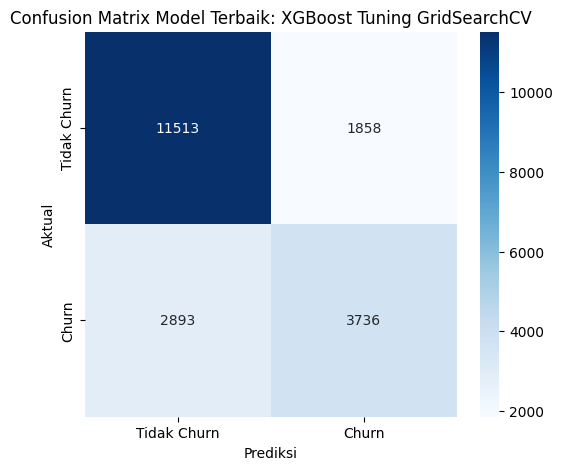

In [ ]:
y_pred_terbaik = model_terbaik.predict(X_test)

cm_terbaik = confusion_matrix(y_test, y_pred_terbaik)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_terbaik,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Tidak Churn', 'Churn'],
    yticklabels=['Tidak Churn', 'Churn']
)

plt.title(f"Confusion Matrix Model Terbaik: {nama_model_terbaik}")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

# **Visualisasi Perbandingan F1-Score Semua Model**

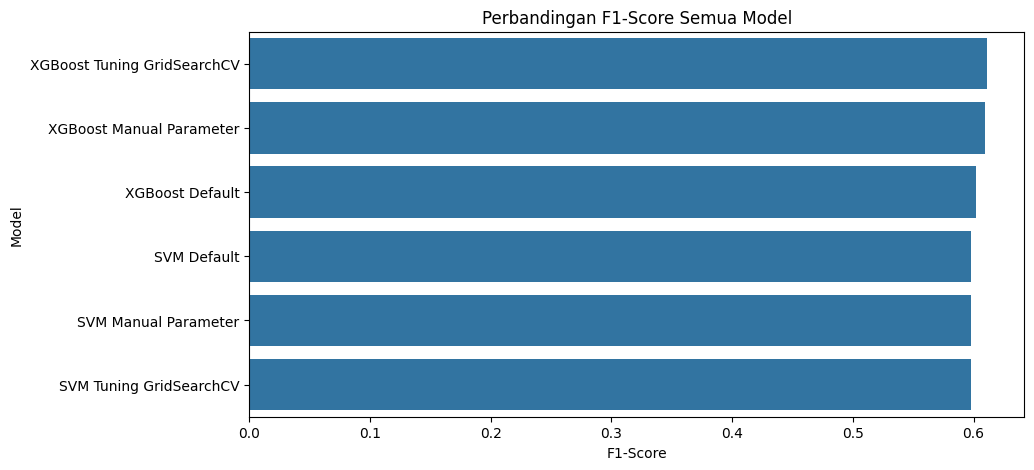

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(
    x='F1-Score',
    y='Kode Model',
    data=df_perbandingan
)
plt.title("Perbandingan F1-Score Semua Model")
plt.xlabel("F1-Score")
plt.ylabel("Model")
plt.show()

# **Feature Importance XGBoost Terbaik**

In [ ]:
df_xgb = df_perbandingan[df_perbandingan['Model'] == 'XGBoost'].copy()
xgb_terbaik_key = df_xgb.iloc[0]['Kode Model']
xgb_terbaik = models[xgb_terbaik_key][2]

print("Model XGBoost terbaik:", xgb_terbaik_key)

try:
    feature_names = xgb_terbaik.named_steps['preprocess'].get_feature_names_out()
    selected_mask = xgb_terbaik.named_steps['select'].get_support()
    selected_features = feature_names[selected_mask]
except:
    selected_features = [f"Feature_{i}" for i in range(K_BEST)]

importance = xgb_terbaik.named_steps['model'].feature_importances_

df_importance = pd.DataFrame({
    'Feature': selected_features,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

display(df_importance)

Model XGBoost terbaik: XGBoost Tuning GridSearchCV


,Feature,Importance
5,cat__Contract_Month-to-month,0.482501
4,cat__Gender_Female,0.129566
9,cat__PaymentMethod_Electronic check,0.103684
1,num__Tenure,0.090310
8,cat__PaymentMethod_Credit card,0.089438
2,num__MonthlyCharges,0.061565
6,cat__Contract_One year,0.026560
7,cat__Contract_Two year,0.010957
0,num__Age,0.002811
3,num__TotalCharges,0.002607


# **Visualisasi Feature Importance XGBoost**

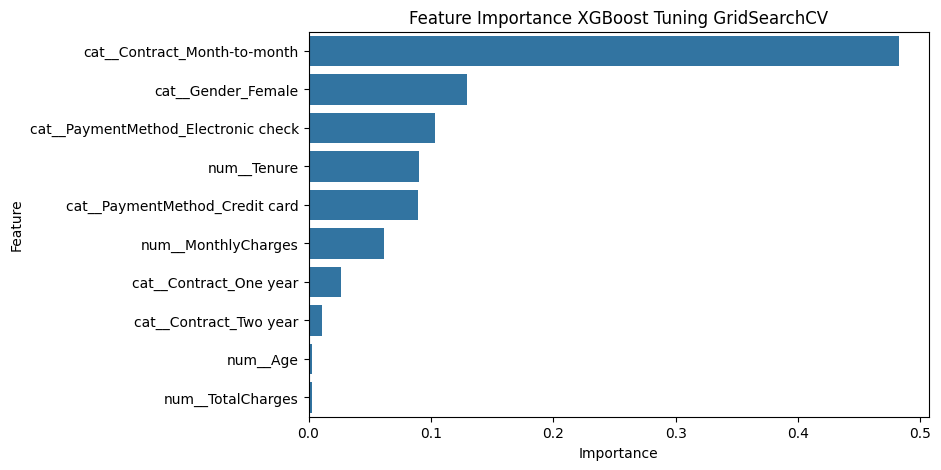

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(
    x='Importance',
    y='Feature',
    data=df_importance
)
plt.title(f"Feature Importance {xgb_terbaik_key}")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

# **Hasil Prediksi Customer Churn**

In [ ]:
hasil_prediksi = pd.DataFrame({
    'CustomerID': id_test.values,
    'Aktual': y_test.values,
    'Prediksi': y_pred_terbaik
})

hasil_prediksi['Aktual'] = hasil_prediksi['Aktual'].map({
    0: 'Tidak Churn',
    1: 'Churn'
})

hasil_prediksi['Prediksi'] = hasil_prediksi['Prediksi'].map({
    0: 'Tidak Churn',
    1: 'Churn'
})

hasil_prediksi = hasil_prediksi.reset_index(drop=True)

display(hasil_prediksi.head(20))

,CustomerID,Aktual,Prediksi
0,82166,Tidak Churn,Tidak Churn
1,87165,Tidak Churn,Tidak Churn
2,17249,Tidak Churn,Tidak Churn
3,92853,Tidak Churn,Tidak Churn
4,22026,Tidak Churn,Churn
5,98257,Churn,Churn
6,84955,Tidak Churn,Tidak Churn
7,64944,Tidak Churn,Tidak Churn
8,86755,Tidak Churn,Tidak Churn
9,77589,Tidak Churn,Tidak Churn
